# 02 · Cleaning and EDA

**Goal:** understand the merged market data, decide how to clean it, and find evidence that market regimes actually exist, before any modelling.

**Input:** `data/processed/merged.csv` (made by `python -m src.data`)
**Output:** `data/processed/clean.csv`, `data/processed/returns.csv`, `data/processed/cleaning_log.csv` (all plain CSV you can open in Excel or VS Code), and figures in `reports/figures/`

Every step has three parts: **What** we do, **Why** it matters, and **Look for** (what to check in the output). Run the cells in order and write your own observations in the final cell.

## Step 0 · Setup

Imports, plotting style, and paths. The notebook works whether you start Jupyter from the repo root or from `notebooks/`.

In [19]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (11, 4)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

def save_fig(name):
    """Save the current figure to reports/figures and show it."""
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"eda_{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

## Step 1 · First look at the data

**What:** load the merged file and check its basic structure: size, date range, column types, and whether dates are sorted and unique.

**Why:** every later step assumes a clean time index. A duplicated or unsorted date would silently break rolling windows and returns.

**Look for:** index sorted = `True`, duplicate dates = `0`, all columns numeric (`float64`), and a date range that starts around 2008 and ends recently.

In [20]:
PROC = ROOT / "data" / "processed"
CSV_PATH = PROC / "merged.csv"
OLD_PARQUET = PROC / "merged.parquet"

if CSV_PATH.exists():
    df = pd.read_csv(CSV_PATH, index_col="Date", parse_dates=True)
elif OLD_PARQUET.exists():
    # one-time conversion of the earlier parquet file to a readable CSV
    df = pd.read_parquet(OLD_PARQUET)
    df.index.name = "Date"
    df.to_csv(CSV_PATH, index_label="Date")
    print("Converted merged.parquet -> merged.csv")
else:
    raise FileNotFoundError("merged.csv not found. Run: python -m src.data")

df.index = pd.to_datetime(df.index)
df = df.sort_index()

print("Shape:", df.shape)
print("Date range:", df.index.min().date(), "to", df.index.max().date())
print("Index sorted:", df.index.is_monotonic_increasing,
      "| duplicate dates:", df.index.duplicated().sum())
print()
print(df.dtypes)

Converted merged.parquet -> merged.csv
Shape: (4610, 8)
Date range: 2008-01-01 to 2026-10-16
Index sorted: True | duplicate dates: 0

nifty50      float64
banknifty    float64
india_vix    float64
usdinr       float64
gold         float64
crude        float64
sp500        float64
us10y        float64
dtype: object


In [21]:
display(df.head())
display(df.tail())

,nifty50,banknifty,india_vix,usdinr,gold,crude,sp500,us10y
Date,,,,,,,,
2008-01-01,6144.350098,9905.134766,NaN,39.244999,NaN,NaN,NaN,NaN
2008-01-02,6179.399902,10250.730469,NaN,39.375000,857.000000,99.620003,1447.160034,3.901
2008-01-03,6178.549805,10100.583008,NaN,39.353001,866.400024,99.180000,1447.160034,3.901
2008-01-04,6274.299805,10233.081055,NaN,39.095001,863.099976,97.910004,1411.630005,3.854
2008-01-07,6279.100098,10390.978516,NaN,39.213001,859.599976,95.089996,1416.180054,3.839


,nifty50,banknifty,india_vix,usdinr,gold,crude,sp500,us10y
Date,,,,,,,,
2026-10-12,22363.349609,54918.000000,15.25,96.775299,4190.600098,93.739998,7807.240234,5.240
2026-10-13,22721.949219,55481.050781,14.12,95.775902,4177.299805,94.139999,7805.450195,5.217
2026-10-14,22622.699219,55316.000000,14.63,95.287201,4107.899902,95.089996,7718.939941,5.190
2026-10-15,22997.349609,55810.500000,14.03,95.151299,4170.100098,97.970001,7744.060059,5.089
2026-10-16,23146.150391,55844.000000,14.06,94.524803,4181.100098,99.019997,7659.439941,5.098


## Step 2 · Missing values

**What:** count missing values per column, find when each series first and last has data, and see how missingness is spread across years.

**Why:** the series do not all start on the same day (India VIX often starts later than the Nifty), and different markets have different holidays. We must know *where* the gaps are before choosing how to fill or drop them.

**Look for:**
- A column with a late `first_valid` date. That column limits how far back the combined dataset can go.
- Gaps scattered through the middle of a series (holidays, data errors) versus one long block at the start.

,missing,missing_%,first_valid,last_valid
nifty50,0,0.00,2008-01-01,2026-10-16
banknifty,0,0.00,2008-01-01,2026-10-16
india_vix,44,0.95,2008-03-03,2026-10-16
usdinr,13,0.28,2008-01-01,2026-10-16
gold,1,0.02,2008-01-02,2026-10-16
crude,1,0.02,2008-01-02,2026-10-16
sp500,1,0.02,2008-01-02,2026-10-16
us10y,1,0.02,2008-01-02,2026-10-16


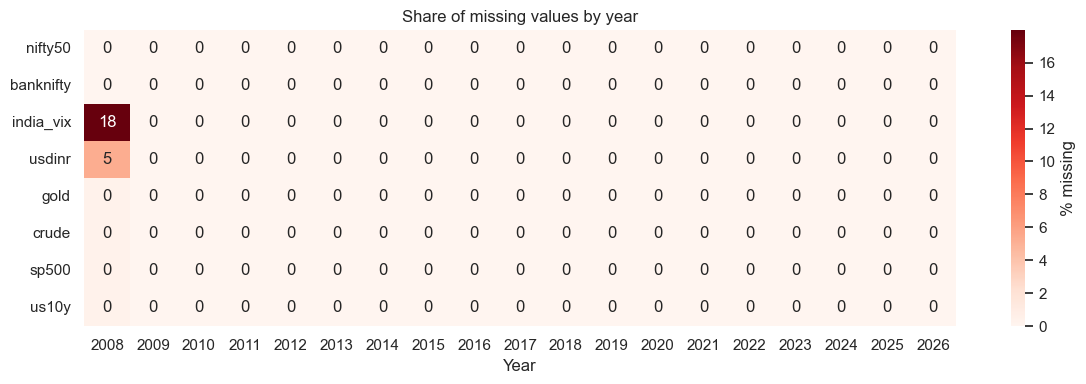

In [22]:
missing = pd.DataFrame({
    "missing": df.isna().sum(),
    "missing_%": (df.isna().mean() * 100).round(2),
    "first_valid": df.apply(lambda s: s.first_valid_index()),
    "last_valid": df.apply(lambda s: s.last_valid_index()),
})
display(missing)

yearly_missing = df.isna().groupby(df.index.year).mean().T * 100
plt.figure(figsize=(12, 4))
sns.heatmap(yearly_missing, annot=True, fmt=".0f", cmap="Reds",
            cbar_kws={"label": "% missing"})
plt.title("Share of missing values by year")
plt.xlabel("Year")
save_fig("missing_by_year")

## Step 3 · Data quality checks

**What:** look for values that cannot be right: zero or negative prices, series stuck at the same value for long runs (stale data), and how often a value does not change from one day to the next.

**Why:** Yahoo Finance data is free but not perfect. A bad value becomes a fake 100% return later and can distort scaling and clustering.

**Look for:**
- Non-positive counts should be `0` for all columns.
- A very long flat run (dozens of days) suggests stale or broken data for that series.

In [23]:
def longest_flat_run(s):
    """Longest streak of identical consecutive values."""
    s = s.dropna()
    return (s != s.shift()).cumsum().value_counts().max()

quality = pd.DataFrame({
    "non_positive": (df <= 0).sum(),
    "days_unchanged_%": ((df.diff() == 0).mean() * 100).round(2),
    "longest_flat_run_days": df.apply(longest_flat_run),
})
quality

,non_positive,days_unchanged_%,longest_flat_run_days
nifty50,0,0.09,2
banknifty,0,0.02,2
india_vix,0,1.26,2
usdinr,0,1.02,4
gold,0,3.10,3
crude,1,3.08,3
sp500,0,2.80,3
us10y,0,4.21,3


## Step 4 · Cleaning decisions

**What:** (a) pick the date range where all required series exist, (b) fill short remaining gaps, (c) drop what is left, and (d) report how many rows each step removed.

**Why:** clustering and classifiers cannot handle `NaN`. We fill only short gaps, because forward-filling a long gap would invent a flat market that never happened.

**Decision to make:** `REQUIRED` lists the columns that must be present. If one series (usually `india_vix`) starts so late that it cuts out important history such as 2008, remove it from `REQUIRED` and drop that column, or accept the shorter sample. Check the `first_valid` table from Step 2 and decide.

In [24]:
REQUIRED = list(df.columns)   # edit this list if a series starts too late

common_start = max(df[c].first_valid_index() for c in REQUIRED)
print("Common start date:", common_start.date())

clean = df.loc[common_start:, REQUIRED].copy()
rows_after_range = len(clean)

clean = clean.ffill(limit=5)          # fill gaps of at most 5 trading days
clean = clean.dropna()                # drop anything still missing

print(f"Rows in raw merged file : {len(df)}")
print(f"Rows after date range   : {rows_after_range}")
print(f"Rows after fill + drop  : {len(clean)}")
print("Missing values left     :", int(clean.isna().sum().sum()))
print("Final range:", clean.index.min().date(), "to", clean.index.max().date())

Common start date: 2008-03-03
Rows in raw merged file : 4610
Rows after date range   : 4566
Rows after fill + drop  : 4558
Missing values left     : 0
Final range: 2008-03-03 to 2026-10-16


In [25]:
dropped = df.loc[common_start:].index.difference(clean.index)
print(f"Dates dropped inside the sample: {len(dropped)}")
if len(dropped):
    print([d.date().isoformat() for d in dropped])
    print("\nMissing values on those dates, per column:")
    print(df.loc[dropped].isna().sum()[lambda x: x > 0])

Dates dropped inside the sample: 8
['2008-08-13', '2008-08-14', '2008-08-18', '2008-08-19', '2008-08-20', '2008-08-21', '2008-08-22', '2008-08-25']

Missing values on those dates, per column:
usdinr    8
dtype: int64


## Step 4b · Bad values: non-positive prices and one-day spikes

**What:** two targeted fixes, each written to a log so nothing is changed silently.
1. **Non-positive prices.** A log return needs a positive price. A real example is WTI crude on 20 April 2020, when the futures price went negative. We treat such a value as missing and carry the previous price forward.
2. **One-day spikes.** A very large move that is almost completely reversed the next day (for example +6% then -6%) is the signature of a bad tick, not a real market move. We treat that day's value as missing and carry the previous price forward. Real crashes and rallies do not reverse this cleanly, so they are not touched.

**Why:** one bad price becomes an impossible return, and it distorts volatility, scaling, and clustering. Without fix 1, the log of a negative price also produces `NaN`, which would delete that date for *every* column later.

**Look for:** the log table below. Every row is a value we changed. Check each one makes sense. If a row is a real move you want to keep, change `k` or `keep` in `find_spikes`.

In [26]:
LEVEL_COLS = [c for c in ["india_vix", "us10y"] if c in clean.columns]
PRICE_COLS = [c for c in clean.columns if c not in LEVEL_COLS]
MARKET = "nifty50" if "nifty50" in clean.columns else clean.columns[0]
fix_log = []

# (a) non-positive prices
for c in PRICE_COLS:
    for d in clean.index[clean[c] <= 0]:
        fix_log.append((d.date(), c, "non-positive price", float(clean.loc[d, c])))
    clean[c] = clean[c].where(clean[c] > 0).ffill()

# (b) one-day spikes that reverse almost completely the next day
def find_spikes(s, k=10, keep=0.15):
    r = np.log(s).diff()
    nxt = r.shift(-1)
    big = r.abs() > k * r.std()
    reversed_next = (r * nxt < 0) & ((r + nxt).abs() < keep * r.abs())
    return r.index[big & reversed_next]

for c in PRICE_COLS:
    for d in find_spikes(clean[c]):
        fix_log.append((d.date(), c, "one-day spike reversed next day", float(clean.loc[d, c])))
        clean.loc[d, c] = np.nan
    clean[c] = clean[c].ffill()

fixes = pd.DataFrame(fix_log, columns=["date", "column", "problem", "bad_value"])
print(f"{len(fixes)} value(s) fixed")
fixes

3 value(s) fixed


,date,column,problem,bad_value
0,2020-04-20,crude,non-positive price,-37.630001
1,2012-01-30,usdinr,one-day spike reversed next day,49.388000
2,2012-01-31,usdinr,one-day spike reversed next day,52.493000


## Step 5 · Look at the levels

**What:** plot every price-like series rebased to 100 on a log scale, then plot the two non-price series (India VIX and the US 10Y yield) as plain levels.

**Why:** raw prices are on completely different scales (Nifty in thousands, USD/INR near 60 to 90). Rebasing puts them on one chart so you can compare growth and see which assets moved together.

**Look for:** long upward trends in the indices, the 2008 and 2020 crashes, and VIX spikes at the same moments. This is the first visual sign that markets behave differently at different times.

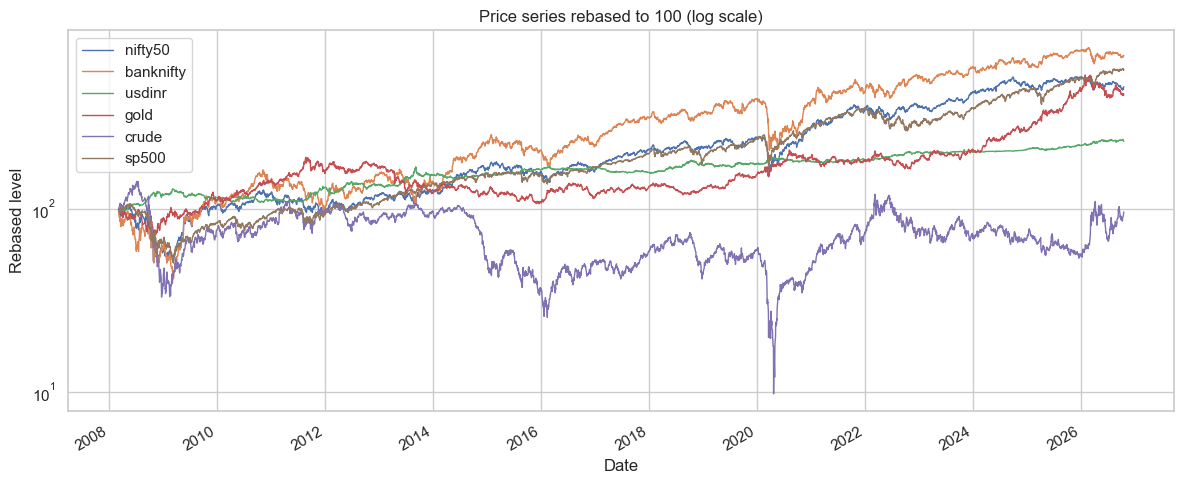

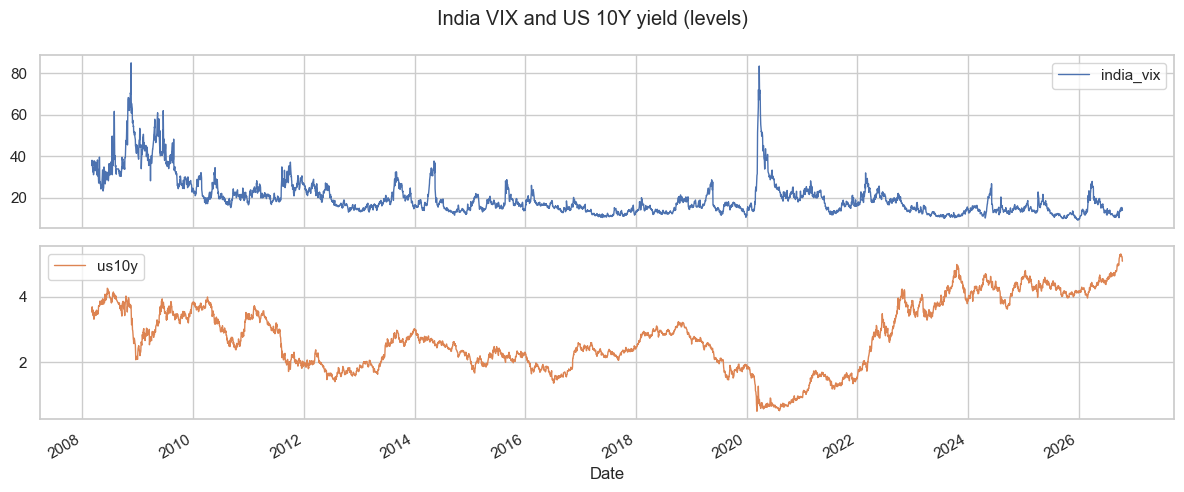

In [27]:
rebased = clean[PRICE_COLS] / clean[PRICE_COLS].iloc[0] * 100
ax = rebased.plot(logy=True, figsize=(12, 5), linewidth=1)
ax.set_title("Price series rebased to 100 (log scale)")
ax.set_ylabel("Rebased level")
save_fig("rebased_prices")

if LEVEL_COLS:
    clean[LEVEL_COLS].plot(subplots=True, figsize=(12, 5), linewidth=1,
                           title="India VIX and US 10Y yield (levels)")
    save_fig("level_series")

## Step 6 · The main market series with known crises

**What:** plot the Nifty 50 and shade periods we know were stressful.

**Why:** later, our clustering will find regimes with no labels. These shaded periods are a sanity check: a good regime model should flag them as high-risk without being told.

**Look for:** whether the shaded periods match falls in the index. We use these dates only for checking, never as model input.

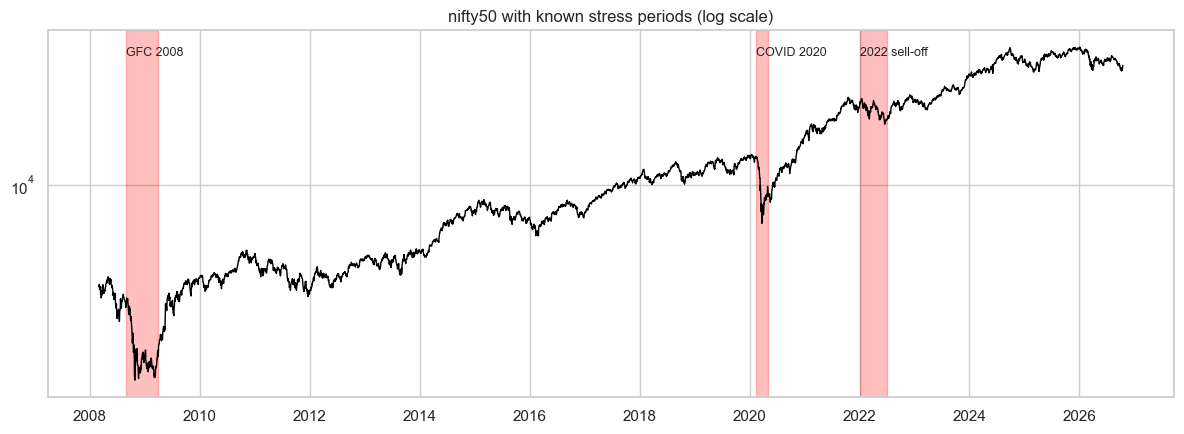

In [28]:
EVENTS = {
    "GFC 2008": ("2008-09-01", "2009-03-31"),
    "COVID 2020": ("2020-02-15", "2020-04-30"),
    "2022 sell-off": ("2022-01-01", "2022-06-30"),
}

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(clean[MARKET], linewidth=1, color="black")
ax.set_yscale("log")
for label, (start, end) in EVENTS.items():
    if pd.Timestamp(end) >= clean.index.min() and pd.Timestamp(start) <= clean.index.max():
        ax.axvspan(pd.Timestamp(start), pd.Timestamp(end), alpha=0.25, color="red")
        ax.text(pd.Timestamp(start), clean[MARKET].max(), label, fontsize=9, va="top")
ax.set_title(f"{MARKET} with known stress periods (log scale)")
save_fig("market_with_events")

## Step 7 · Convert prices to returns

**What:** turn price levels into daily returns: log returns for prices, and simple differences for the US 10Y yield (a yield is already a rate, so we measure its change in percentage points).

**Why:** prices trend upward forever, so they are not stable over time (non-stationary). Returns fluctuate around a steady centre, which is what clustering and classifiers need. Log returns also add up over time and make the series comparable.

**Look for:** daily means very close to zero, and a few extreme days. The top-10 table shows the largest Nifty moves. They should fall in known crisis periods. If one appears in a calm period, check whether it is a data error.

In [29]:
returns = pd.DataFrame(index=clean.index)
for c in clean.columns:
    if c == "us10y":
        returns[c] = clean[c].diff()            # change in yield (percentage points)
    else:
        returns[c] = np.log(clean[c]).diff()    # log return
returns = returns.dropna()

display(returns.describe().T.round(5))

top = returns[MARKET].reindex(returns[MARKET].abs().sort_values(ascending=False).head(10).index)
print(f"\nTen largest daily moves in {MARKET} (%):")
(top * 100).round(2).to_frame("return_%")

,count,mean,std,min,25%,50%,75%,max
nifty50,4557.0,0.00034,0.01252,-0.13904,-0.00518,0.00055,0.00636,0.16334
banknifty,4557.0,0.00043,0.01684,-0.18313,-0.00695,0.00066,0.00802,0.17239
india_vix,4557.0,-0.00020,0.05799,-0.47020,-0.02859,-0.00249,0.02551,0.50456
usdinr,4557.0,0.00019,0.00491,-0.05871,-0.00212,0.00003,0.00235,0.04866
gold,4557.0,0.00032,0.01181,-0.11406,-0.00493,0.00025,0.00605,0.08643
crude,4557.0,-0.00001,0.02953,-0.60168,-0.01215,0.00025,0.01266,0.33316
sp500,4557.0,0.00038,0.01258,-0.12765,-0.00406,0.00049,0.00580,0.10957
us10y,4557.0,0.00034,0.05803,-0.47000,-0.03200,0.00000,0.03300,0.33200



Ten largest daily moves in nifty50 (%):


,return_%
Date,
2009-05-18,16.33
2020-03-23,-13.90
2008-10-24,-13.01
2020-03-12,-8.67
2020-04-07,8.40
2020-03-16,-7.92
2008-11-11,-6.89
2008-10-10,-6.88
2008-10-31,6.76


## Step 8 · Summary statistics of returns

**What:** annualise the mean and volatility (multiply by 252 trading days, or by its square root for volatility), and compute skewness, kurtosis, and the best and worst days.

**Why:** these numbers compare risk across assets. **Excess kurtosis** is the key one. A normal distribution has 0, and market returns typically have much higher values, meaning rare huge moves happen far more often than a bell curve predicts.

**Look for:** gold and the indices having different volatility levels, and positive excess kurtosis everywhere. India VIX and the US 10Y yield are **levels**, not prices, so annualised return and volatility are meaningless for them. They get their own table of daily changes.

In [30]:
TRADING_DAYS = 252
r_price = returns[PRICE_COLS]
summary = pd.DataFrame({
    "mean_ann_%": r_price.mean() * TRADING_DAYS * 100,
    "vol_ann_%": r_price.std() * np.sqrt(TRADING_DAYS) * 100,
    "skew": r_price.skew(),
    "excess_kurtosis": r_price.kurt(),
    "worst_day_%": r_price.min() * 100,
    "best_day_%": r_price.max() * 100,
}).round(2)
display(summary)

if LEVEL_COLS:
    r_level = returns[LEVEL_COLS]
    level_summary = pd.DataFrame({
        "daily_change_std": r_level.std(),
        "skew": r_level.skew(),
        "excess_kurtosis": r_level.kurt(),
        "min_change": r_level.min(),
        "max_change": r_level.max(),
    }).round(3)
    print("\nLevel series (india_vix = log change, us10y = change in percentage points):")
    display(level_summary)

,mean_ann_%,vol_ann_%,skew,excess_kurtosis,worst_day_%,best_day_%
nifty50,8.53,19.88,-0.28,16.55,-13.90,16.33
banknifty,10.71,26.73,-0.21,10.36,-18.31,17.24
usdinr,4.72,7.79,-0.02,12.10,-5.87,4.87
gold,8.01,18.75,-0.43,6.98,-11.41,8.64
crude,-0.19,46.88,-1.66,53.84,-60.17,33.32
sp500,9.68,19.97,-0.45,13.51,-12.77,10.96



Level series (india_vix = log change, us10y = change in percentage points):


,daily_change_std,skew,excess_kurtosis,min_change,max_change
india_vix,0.058,0.584,9.221,-0.47,0.505
us10y,0.058,-0.049,3.005,-0.47,0.332


## Step 9 · Are returns normally distributed?

**What:** compare the histogram of Nifty returns with a normal curve, draw a Q-Q plot (points should follow the straight line if the data is normal), and run the Jarque-Bera test.

**Why:** if returns were normal, one simple model would describe the market at all times. They are not, and that is the statistical reason to look for regimes.

**Look for:** a taller, narrower peak and heavier tails than the red curve, Q-Q points curving away from the line at both ends, and a Jarque-Bera p-value near 0 (normality rejected).

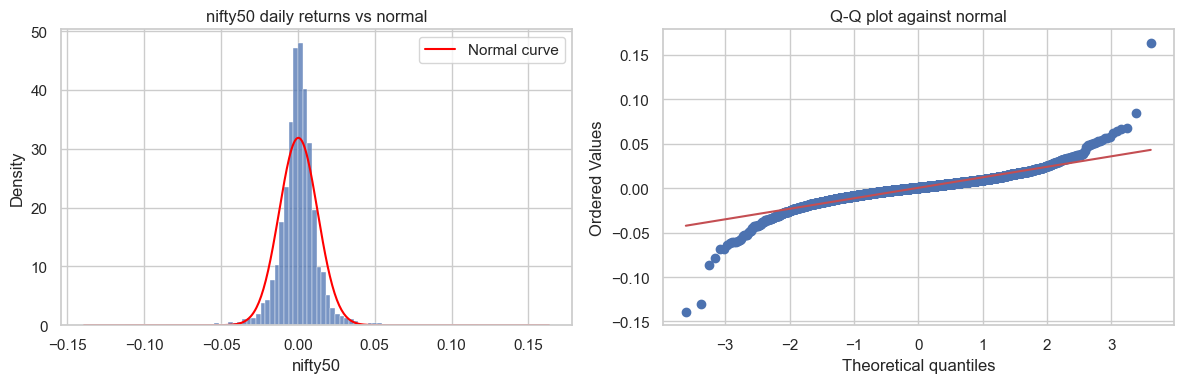

Jarque-Bera statistic = 51973.9, p-value = 0
Normality rejected.


In [31]:
r = returns[MARKET]
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(r, bins=100, stat="density", ax=ax[0])
x = np.linspace(r.min(), r.max(), 400)
ax[0].plot(x, stats.norm.pdf(x, r.mean(), r.std()), color="red", label="Normal curve")
ax[0].set_title(f"{MARKET} daily returns vs normal")
ax[0].legend()

stats.probplot(r, dist="norm", plot=ax[1])
ax[1].set_title("Q-Q plot against normal")
save_fig("return_distribution")

jb_stat, jb_p = stats.jarque_bera(r)
print(f"Jarque-Bera statistic = {jb_stat:.1f}, p-value = {jb_p:.4g}")
print("Normality rejected." if jb_p < 0.05 else "Cannot reject normality.")

## Step 10 · Stationarity check

**What:** run the Augmented Dickey-Fuller (ADF) test on the Nifty price and on its returns.

**Why:** this proves the Step 7 choice. A model trained on a non-stationary series learns the trend, not the behaviour.

**Look for:** the price has a large p-value (cannot reject a unit root, so non-stationary) and the returns have a p-value near 0 (stationary). This cell needs `statsmodels` (`pip install statsmodels`) and is skipped if it is missing.

In [32]:
try:
    from statsmodels.tsa.stattools import adfuller
    for label, s in [(f"{MARKET} price", clean[MARKET]), (f"{MARKET} log return", returns[MARKET])]:
        stat, p = adfuller(s.dropna())[:2]
        verdict = "stationary" if p < 0.05 else "non-stationary"
        print(f"{label:22s} ADF p-value = {p:.4f}  ->  {verdict}")
except ImportError:
    print("statsmodels is not installed. Run: pip install statsmodels")

nifty50 price          ADF p-value = 0.9744  ->  non-stationary
nifty50 log return     ADF p-value = 0.0000  ->  stationary


## Step 11 · Volatility clustering

**What:** plot 21-day rolling volatility next to India VIX, and measure how strongly today's return size predicts tomorrow's using autocorrelation.

**Why:** this is the core evidence for regimes. Returns themselves are almost unpredictable, but their *size* is persistent: calm days follow calm days and turbulent days follow turbulent days. That persistence means the market spends time in distinct states.

**Look for:**
- Rolling volatility rising sharply in crises and staying elevated for weeks or months, with India VIX moving alongside it.
- In the bar charts, autocorrelation of plain returns near zero, but autocorrelation of absolute returns clearly positive and decaying slowly over many lags.

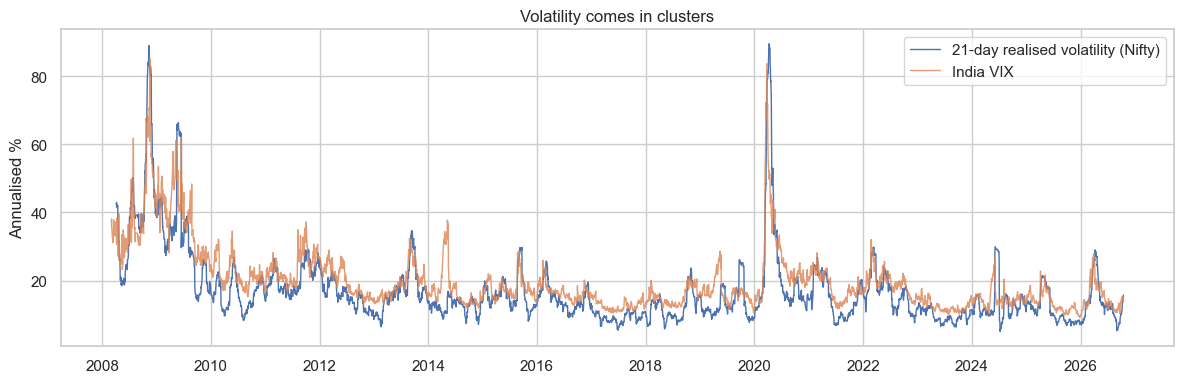

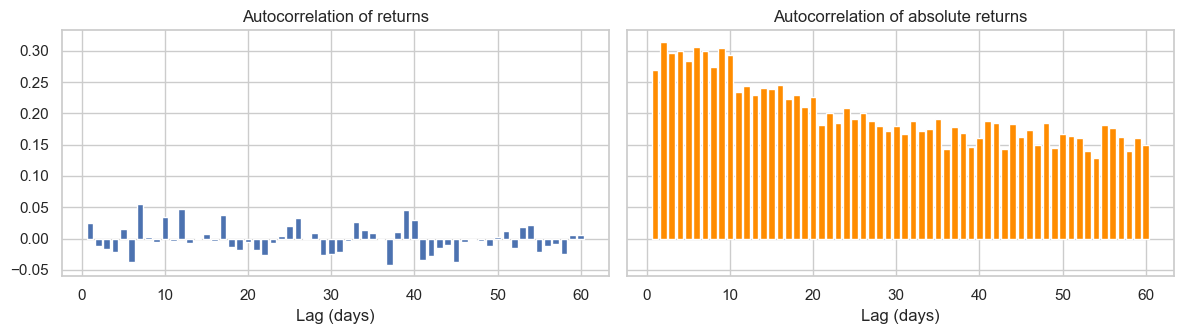

In [33]:
vol21 = returns[MARKET].rolling(21).std() * np.sqrt(TRADING_DAYS) * 100

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(vol21, label="21-day realised volatility (Nifty)", linewidth=1)
if "india_vix" in clean.columns:
    ax.plot(clean["india_vix"].reindex(vol21.index), label="India VIX", linewidth=1, alpha=0.8)
ax.set_ylabel("Annualised %")
ax.set_title("Volatility comes in clusters")
ax.legend()
save_fig("volatility_clustering")

lags = range(1, 61)
acf_ret = [returns[MARKET].autocorr(l) for l in lags]
acf_abs = [returns[MARKET].abs().autocorr(l) for l in lags]

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5), sharey=True)
ax[0].bar(lags, acf_ret); ax[0].set_title("Autocorrelation of returns")
ax[1].bar(lags, acf_abs, color="darkorange"); ax[1].set_title("Autocorrelation of absolute returns")
for a in ax:
    a.set_xlabel("Lag (days)")
save_fig("autocorrelation")

## Step 12 · Correlations

**What:** a correlation heatmap of daily returns, a rolling 63-day correlation between the Nifty and the S&P 500, and a one-day-lag check.

**Why:** assets that are independent in calm markets often move together in a crisis, so correlation itself changes by regime. That is why we use many assets as features instead of one index.

**Look for:**
- Which assets move with the Nifty (Bank Nifty strongly) and which hardly do (gold, crude).
- The rolling correlation jumping up in 2008 and 2020.
- The lag check compares the Nifty with the S&P of the same date and of the previous day. Both can be positive, so the S&P carries information either way.

**Important for modelling (avoiding look-ahead):** Indian markets close *before* the US session. The S&P 500, gold, crude, and US 10Y values on date *t* are only known **after** the Nifty has closed on date *t*. When we later predict the next regime or backtest a strategy, these US-session columns must be **shifted by one day**. Regime *detection* is descriptive, so it does not need the shift.

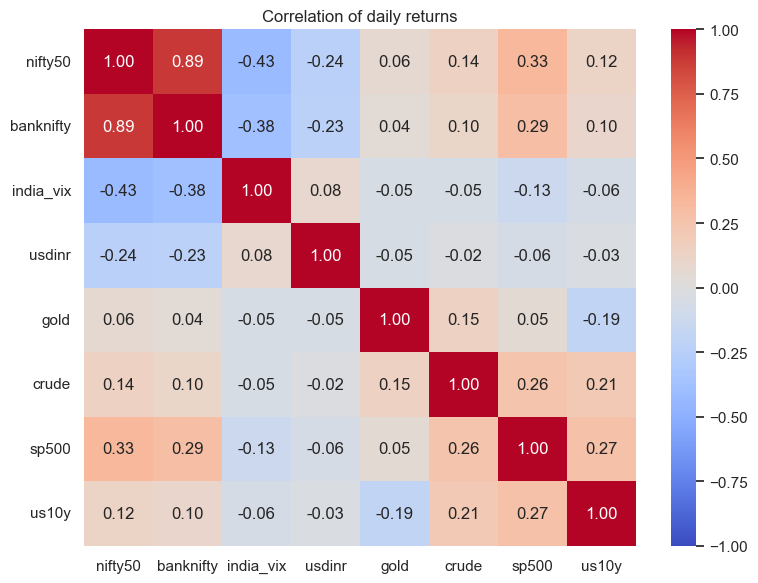

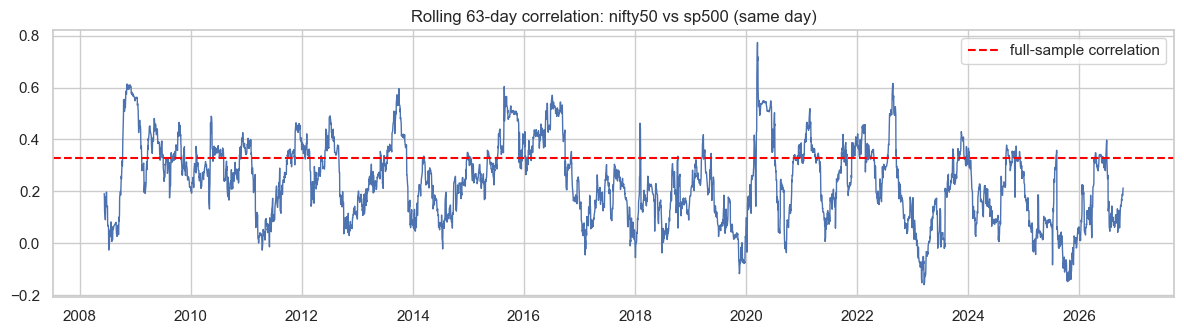

Same-day correlation : 0.329
Lagged (S&P t-1)     : 0.234


In [34]:
plt.figure(figsize=(8, 6))
sns.heatmap(returns.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Correlation of daily returns")
save_fig("correlation_heatmap")

if "sp500" in returns.columns and MARKET != "sp500":
    roll_corr = returns[MARKET].rolling(63).corr(returns["sp500"])
    fig, ax = plt.subplots(figsize=(12, 3.5))
    ax.plot(roll_corr, linewidth=1)
    ax.axhline(returns[MARKET].corr(returns["sp500"]), color="red", linestyle="--",
               label="full-sample correlation")
    ax.set_title(f"Rolling 63-day correlation: {MARKET} vs sp500 (same day)")
    ax.legend()
    save_fig("rolling_correlation")

    same_day = returns[MARKET].corr(returns["sp500"])
    lagged = returns[MARKET].corr(returns["sp500"].shift(1))
    print(f"Same-day correlation : {same_day:.3f}")
    print(f"Lagged (S&P t-1)     : {lagged:.3f}")

## Step 13 · Drawdowns

**What:** measure how far the Nifty is below its previous all-time high at every date, and count how often it is more than 5%, 10%, and 20% below.

**Why:** drawdown is an intuitive stress measure and a good feature for regime detection. The percentages also preview **class imbalance**: if only a few percent of days are deep drawdowns, a "crisis" class will be rare and we must handle that when predicting regimes.

Drawdown is measured from the full Nifty history (from January 2008, before India VIX starts), so the early-2008 peak is included.

**Look for:** the deepest drawdown landing in 2008 or 2020, and a small share of days beyond -20%.

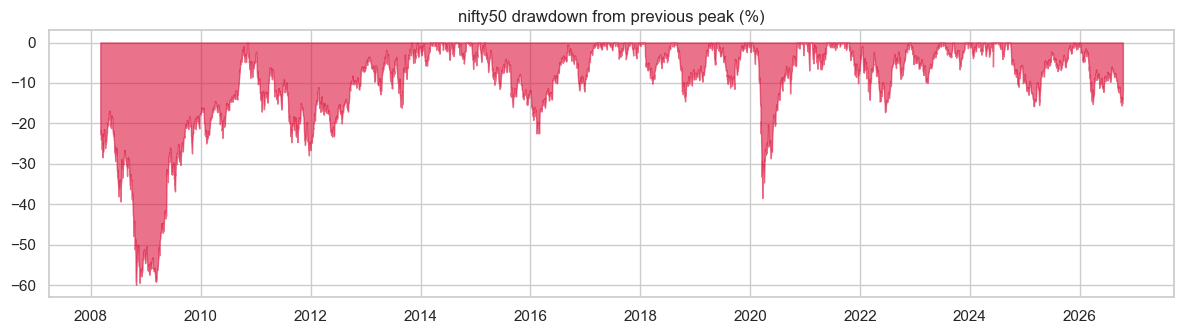

Maximum drawdown: -59.9% on 2008-10-27
Days with drawdown worse than -5%: 57.5%
Days with drawdown worse than -10%: 34.1%
Days with drawdown worse than -20%: 12.7%


In [35]:
full_price = df[MARKET].dropna()
drawdown = (full_price / full_price.cummax() - 1).reindex(clean.index)

fig, ax = plt.subplots(figsize=(12, 3.5))
ax.fill_between(drawdown.index, drawdown * 100, 0, color="crimson", alpha=0.6)
ax.set_title(f"{MARKET} drawdown from previous peak (%)")
save_fig("drawdown")

print(f"Maximum drawdown: {drawdown.min():.1%} on {drawdown.idxmin().date()}")
for th in (0.05, 0.10, 0.20):
    print(f"Days with drawdown worse than -{th:.0%}: {(drawdown < -th).mean():.1%}")

## Step 14 · Year-by-year view

**What:** a table of return, volatility, and worst drawdown for each calendar year.

**Why:** it shows at a glance that years differ sharply in risk, and gives you concrete numbers for the report and Chalk Talk.

**Look for:** high-volatility, deep-drawdown years (typically 2008 and 2020) versus calm, steady-growth years. The first and last years are **partial** (the sample starts in March 2008 and ends in the current year), so their returns are not full calendar-year figures.

In [36]:
by_year = returns[MARKET].groupby(returns.index.year)
yearly = pd.DataFrame({
    "return_%": (np.exp(by_year.sum()) - 1) * 100,
    "volatility_ann_%": by_year.std() * np.sqrt(TRADING_DAYS) * 100,
    "worst_drawdown_%": drawdown.groupby(drawdown.index.year).min() * 100,
    "trading_days": by_year.count(),
}).round(1)
yearly["note"] = ""
yearly.loc[yearly.index[0], "note"] = f"partial year (from {clean.index.min().date()})"
yearly.loc[yearly.index[-1], "note"] = f"partial year (to {clean.index.max().date()})"
yearly

,return_%,volatility_ann_%,worst_drawdown_%,trading_days,note
Date,,,,,
2008,-40.3,45.2,-59.9,192,partial year (from 2008-03-03)
2009,75.8,34.2,-59.1,241,
2010,17.9,16.3,-25.0,250,
2011,-24.6,21.2,-27.9,242,
2012,27.7,15.5,-24.7,242,
2013,6.8,18.2,-16.1,247,
2014,31.4,12.8,-6.5,240,
2015,-4.1,16.4,-16.0,244,
2016,3.0,15.2,-22.5,244,


## Step 15 · Preview: do regimes show up?

**What:** plot each day by its recent return (63-day) and recent volatility (21-day), coloured by drawdown. No model is used here.

**Why:** if the points form separate groups (for example calm and rising, volatile and falling), clustering has something real to find. If they form one uniform blob, regime detection would be hard to justify.

**Look for:** a calm-and-rising cloud, and a high-volatility, negative-return, deeply red group in the crisis corner.

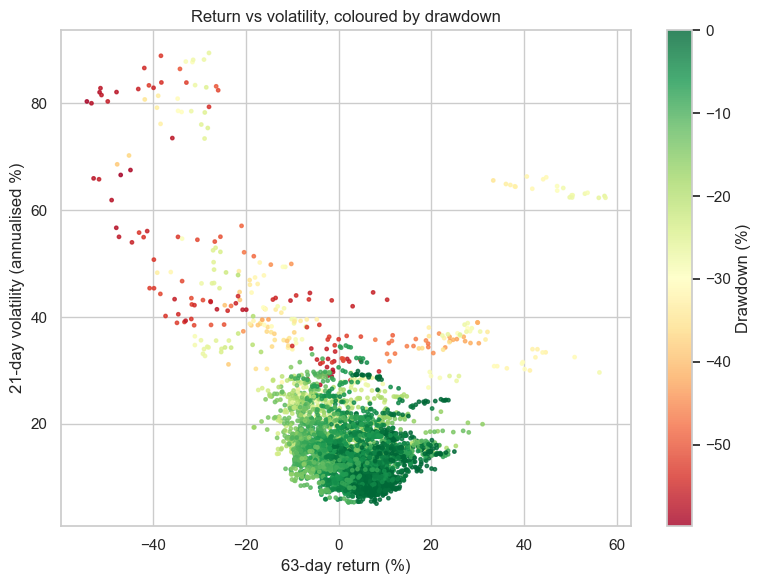

In [37]:
preview = pd.DataFrame({
    "vol21": vol21,
    "ret63": returns[MARKET].rolling(63).sum() * 100,
    "drawdown": drawdown.reindex(returns.index),
}).dropna()

fig, ax = plt.subplots(figsize=(8, 6))
sc = ax.scatter(preview["ret63"], preview["vol21"], c=preview["drawdown"] * 100,
                cmap="RdYlGn", s=6, alpha=0.8)
plt.colorbar(sc, label="Drawdown (%)")
ax.set_xlabel("63-day return (%)")
ax.set_ylabel("21-day volatility (annualised %)")
ax.set_title("Return vs volatility, coloured by drawdown")
save_fig("regime_preview")

## Step 16 · Save the cleaned data

**What:** save the cleaned price levels, the returns, and the cleaning log as plain CSV files.

**Why:** feature engineering and modelling should start from the same cleaned data, not repeat these decisions. CSV files open directly in Excel or VS Code, so you can inspect them. They sit in `data/processed/`, so git ignores them, and anyone can recreate them by running the pipeline and this notebook.

In [38]:
out_dir = ROOT / "data" / "processed"
clean.round(4).to_csv(out_dir / "clean.csv", index_label="Date")
returns.round(6).to_csv(out_dir / "returns.csv", index_label="Date")
fixes.to_csv(out_dir / "cleaning_log.csv", index=False)
print("clean        :", clean.shape, "->", out_dir / "clean.csv")
print("returns      :", returns.shape, "->", out_dir / "returns.csv")
print("cleaning log :", fixes.shape, "->", out_dir / "cleaning_log.csv")

clean        : (4558, 8) -> c:\Users\khush\OneDrive\Desktop\git\Regime-Aware-Adaptive-Trading-Risk-Management-System\data\processed\clean.csv
returns      : (4557, 8) -> c:\Users\khush\OneDrive\Desktop\git\Regime-Aware-Adaptive-Trading-Risk-Management-System\data\processed\returns.csv
cleaning log : (3, 4) -> c:\Users\khush\OneDrive\Desktop\git\Regime-Aware-Adaptive-Trading-Risk-Management-System\data\processed\cleaning_log.csv


## Findings (fill this in after running)

Write two or three lines for each point. These become the "dataset quality" and "motivation" parts of your report and Chalk Talk.

1. **Data quality:** which series had gaps or late starts, and what you decided (Steps 2 to 4).
2. **Final dataset:** number of rows, columns, and date range after cleaning.
3. **Return behaviour:** how heavy are the tails (excess kurtosis, Jarque-Bera result)?
4. **Volatility clustering:** what the autocorrelation of absolute returns showed.
5. **Correlations:** which assets move together, and what changes during crises.
6. **Class balance:** the share of days with drawdown beyond -10% and -20%.
7. **Regime evidence:** did Step 15 show distinct groups?
8. **Cleaning log:** what Step 4b changed (see `cleaning_log.csv`) and why.
9. **Modelling rule:** US-session columns (sp500, gold, crude, us10y) are shifted by one day for prediction and backtesting.